# Rough or Just Noisy?

A reproducible demonstration of how the observation process changes a descriptive volatility-roughness estimate. This notebook uses **synthetic data only**. It does not estimate market spot H, compare trading strategies, or claim a novel estimator.

The fixed full study uses 128 independent paths per model. The small fresh run below is an implementation demonstration; its sampling variation is larger. See `manuscript/SYNTHETIC_STUDY.md` for the full experiment and limitations. AI assistance and human-review status are disclosed in `AI_USE.md`.

In [1]:
from pathlib import Path
import json, sys, copy
import numpy as np
import pandas as pd
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'configs/side_project.json').is_file())
sys.path.insert(0, str(root / 'src'))
from roughnoisy.study import prepare, path_metrics, validate_covariance
cfg = json.loads((root / 'configs/side_project.json').read_text())
print({k: cfg[k] for k in ['models', 'days', 'paths', 'sampling_minutes', 'log_price_noise_sd', 'primary_lag_band']})

{'models': ['OU', 'Cauchy_H01', 'Cauchy_H03'], 'days': 504, 'paths': 128, 'sampling_minutes': [1, 5, 15, 30], 'log_price_noise_sd': [0.0, 0.0001, 0.0003], 'primary_lag_band': 10}


## Independent construction checks

The covariance formula is compared with an independent parametrization, the inverse FFT of the embedding spectrum, and dense Cholesky Gaussian draws. These check the finite-dimensional Gaussian law, not whether the law describes a market.

In [2]:
checks = validate_covariance(cfg)
for check in checks:
    print(check['model'], check['status'], 'FFT max error:', check['FFT_covariance_max_abs_error'])
assert all(c['status'] == 'passed_checks' for c in checks)

OU passed_checks FFT max error: 5.551115123125783e-17
Cauchy_H01 passed_checks FFT max error: 1.3877787807814457e-16
Cauchy_H03 passed_checks FFT max error: 1.1102230246251565e-16


## Run a small fresh experiment

For every path: simulate log spot variance, integrate on the fine trading-clock grid, simulate conditional Gaussian log-price returns, add endpoint price noise, and construct nested RV measures. Means below use four paths/model and are not the frozen full-study estimates.

In [3]:
fresh = []
for model in cfg['models']:
    spectrum, _ = prepare(model, cfg)
    for replicate in range(4):
        fresh.extend(path_metrics(model, cfg, replicate, spectrum))
fresh = pd.DataFrame(fresh)
small = fresh[(fresh.noise_sd == 0) & (fresh.lag_max == 10) & (fresh.sampling_minutes == 5)]
display(small.groupby('model')[['local_H', 'H_spot', 'H_IV', 'H_RV']].mean().round(3))
assert np.isfinite(fresh.select_dtypes(include='number')).all().all()

,local_H,H_spot,H_IV,H_RV
model,,,,
Cauchy_H01,0.1,0.071,0.237,0.123
Cauchy_H03,0.3,0.212,0.321,0.193
OU,0.5,0.441,0.514,0.201


## Read the fixed full-study results

The committed summary is synthetic. H-tilde is half the log-variogram slope over lags 1–10. Different columns describe different observed objects; none should automatically equal the local spot exponent.

In [4]:
columns = ['model', 'noise_sd', 'sampling_minutes', 'lag_max', 'local_H', 'H_spot_mean', 'H_IV_mean', 'H_RV_mean', 'H_RV_mcse', 'run_id']
pd.read_csv(root / 'results/side_project/summary.csv', usecols=columns, nrows=5)
full = pd.read_csv(root / 'results/side_project/summary.csv', usecols=columns)
selected = full[(full.noise_sd == 0) & (full.lag_max == 10) & (full.sampling_minutes == 5)]
display(selected[['model', 'local_H', 'H_spot_mean', 'H_IV_mean', 'H_RV_mean', 'H_RV_mcse']].round(4))
print('Full-study run:', full.run_id.iloc[0])

,model,local_H,H_spot_mean,H_IV_mean,H_RV_mean,H_RV_mcse
4,Cauchy_H01,0.1,0.0736,0.2411,0.1241,0.0019
40,Cauchy_H03,0.3,0.2173,0.3311,0.1952,0.0023
76,OU,0.5,0.4670,0.5392,0.2379,0.0026


Full-study run: side_project_study_20261021T214152Z


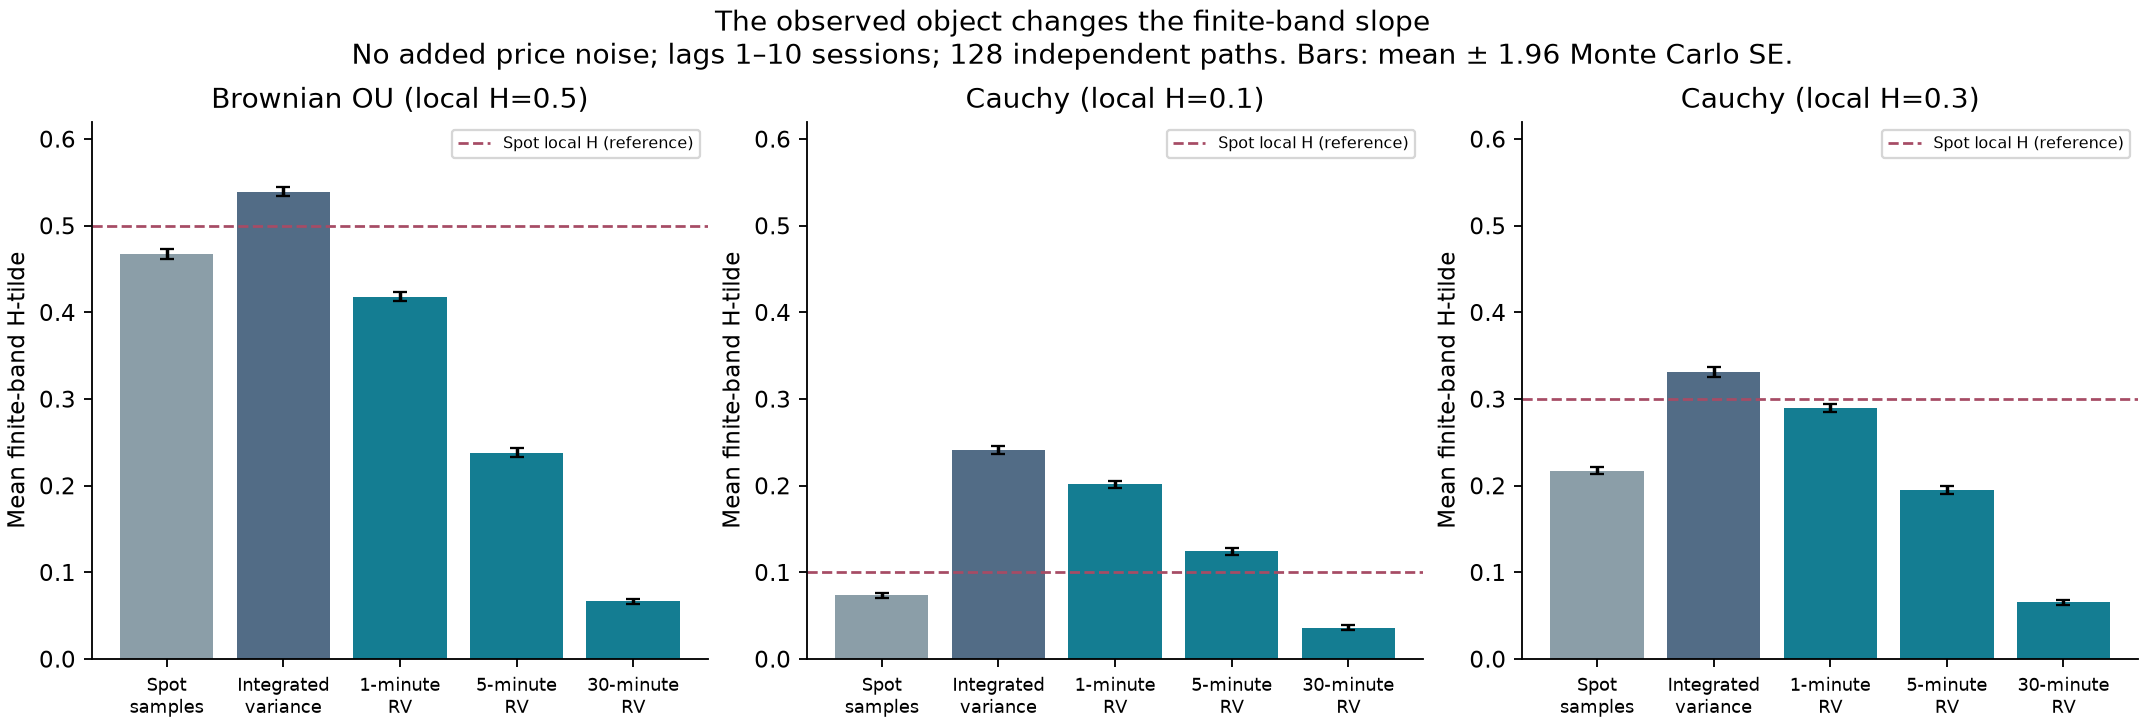

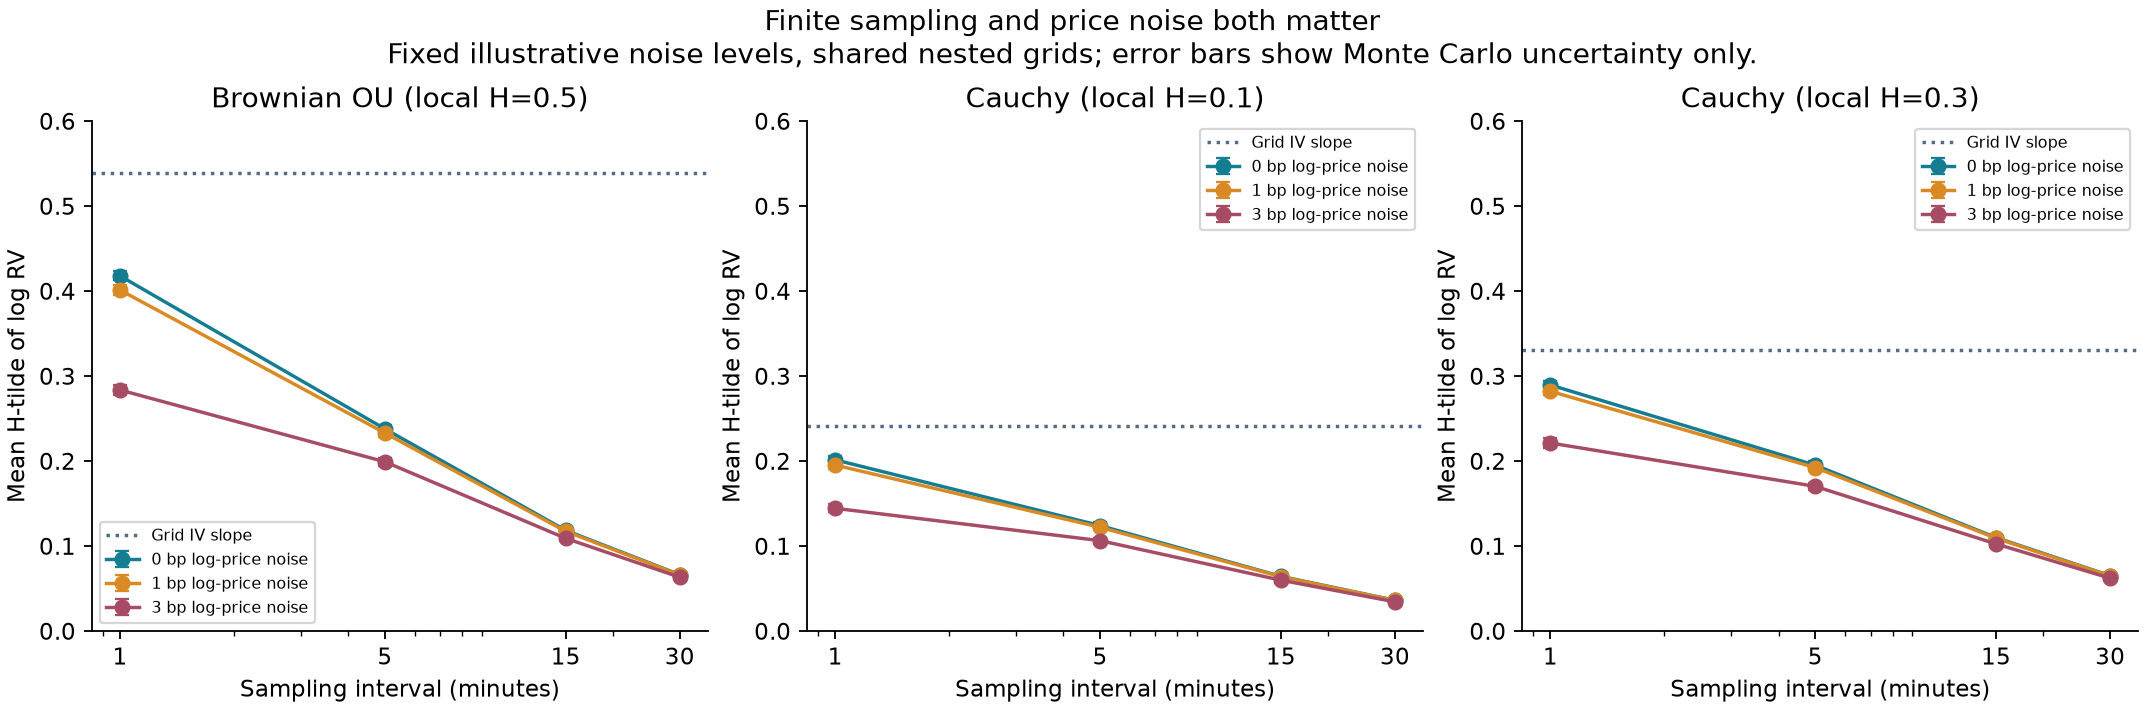

In [5]:
from IPython.display import Image, display
display(Image(filename=str(root / 'docs/figures/measurement_chain.png')))
display(Image(filename=str(root / 'docs/figures/sampling_noise.png')))

## What follows—and what does not

The OU counterexample shows that a low naive slope from log RV need not identify rough spot volatility. Temporal aggregation and finite return sampling matter even without added price noise. Conversely, this example does not establish that actual volatility is smooth, and accounting for measurement error does not guarantee H=0.5.

The figures show mean ±1.96 Monte Carlo SE across independent paths. They do not provide coverage for an estimator of market H. Noise levels are illustrative, model parameters are fixed, integration uses a finite trading clock, and the empirical forecasting extension remains deferred.

To extend the demonstration, predict the effect of a different sampling grid before changing a separate config. Preserve the frozen study and report both results.